# Solar filament instance segmentation — full inference pipeline

This notebook reproduces the submitted predictions from the stored weights (no training):

1. load the H-alpha test frames,
2. predict filament / spine probability maps with the cross-validation ensemble (8-view test-time augmentation),
3. build the threshold component tree, score every candidate mask (expected matched IoU) and select the PQ-optimal pixel-disjoint subset,
4. write `submission.csv` (one COCO RLE per filament) and validate it,
5. show a few results, and (optionally) score held-out training images with the organisers' metric.

Only the competition files are needed: `DATA/test/test_images/*.jpeg` (and the train folder for the optional last section).

In [1]:
import sys, json, time
from pathlib import Path
import numpy as np, cv2, torch
import matplotlib.pyplot as plt

REPO = Path.cwd()                      # run from the repository root
sys.path.insert(0, str(REPO))
DATA = Path("data/raw/MAGFiLO_1.0_Kaggle_2026")   # <- adjust to where the competition data was unzipped
WEIGHTS = REPO / "weights"

from fil import rle
from fil.pipeline import FilamentSegmenter
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


torch 2.9.1+cu128 | cuda: True


## 1. Model

`FilamentSegmenter` bundles the five fold networks (U-Net, EfficientNetV2-S encoder, inputs = image + disk coordinates),
the LightGBM candidate scorer and the selection threshold `lambda` (the PQ level; a mask is kept iff its expected matched
IoU exceeds `lambda / 2` and no better combination of nested masks exists).

In [2]:
seg = FilamentSegmenter.from_dir(WEIGHTS, device="cuda" if torch.cuda.is_available() else "cpu")
print(len(seg.models), "networks |", len(seg.boosters), "scorers |", len(seg.feats), "descriptors | lambda =", seg.lam)

5 networks | 5 scorers | 54 descriptors | lambda = 0.6


## 2. Inference on the test set

In [3]:
def read_gray(path):
    im = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    return im if im.ndim == 2 else im[..., 0]

files = sorted((DATA / "test/test_images").glob("*.jpeg"))
pred, keep = {}, {}
t0 = time.time()
for k, f in enumerate(files):
    img = read_gray(f)
    res = seg.segment(img)
    if len(res.stats):
        pred[f.stem] = res.rles()
    if k < 4:
        keep[f.stem] = (img, res)
    if (k + 1) % 20 == 0:
        print(f"{k + 1}/{len(files)} images, {(time.time() - t0) / (k + 1):.1f} s/image")
print("filaments:", sum(len(v) for v in pred.values()), "in", len(pred), "images")

20/180 images, 2.8 s/image


40/180 images, 2.7 s/image


60/180 images, 2.7 s/image


80/180 images, 2.7 s/image


100/180 images, 2.7 s/image


120/180 images, 2.7 s/image


140/180 images, 2.7 s/image


160/180 images, 2.7 s/image


180/180 images, 2.7 s/image
filaments: 1071 in 177 images


## 3. Submission file

In [4]:
rle.write_submission(pred, "submission.csv")
print(rle.check_submission("submission.csv", {f.stem for f in files}))   # decodable, unique ids, pixel-disjoint

{'rows': 1071, 'images': 177, 'mean_per_image': 6.0508474576271185}


## 4. A look at the result

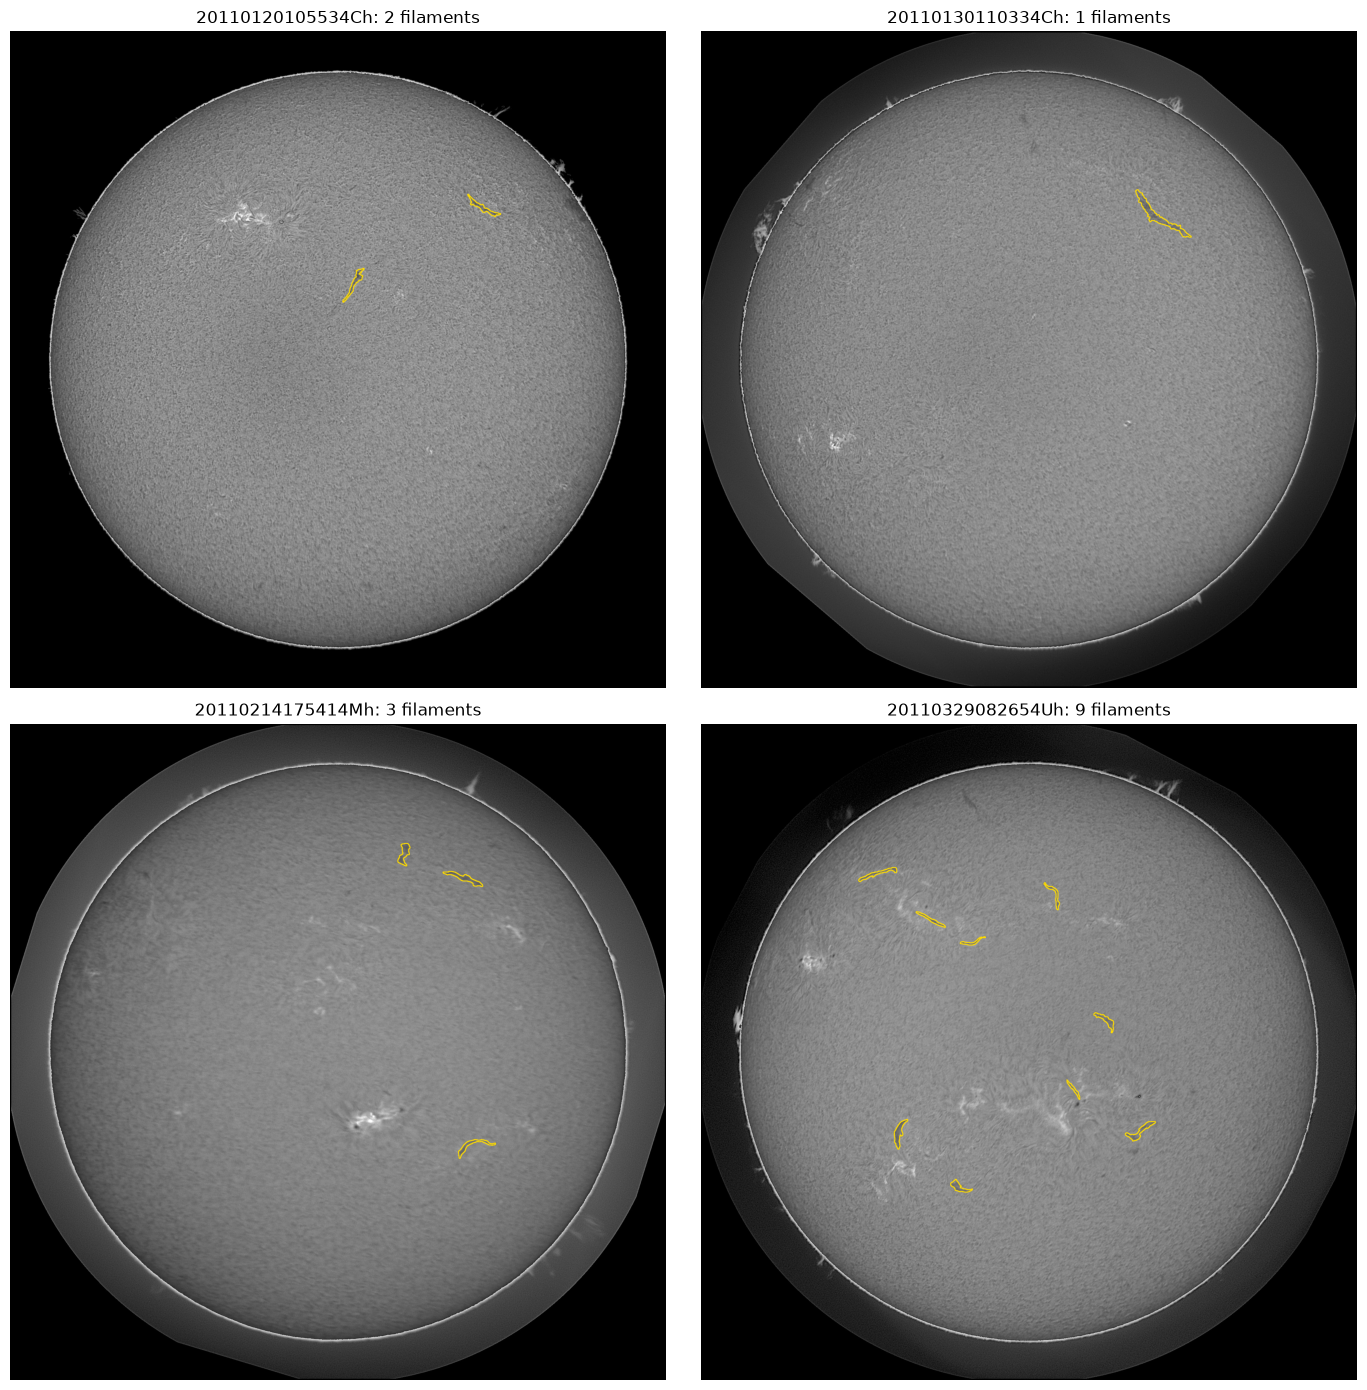

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 14))
for ax, (stem, (img, res)) in zip(axes.ravel(), keep.items()):
    vis = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    for i in range(1, int(res.labels.max()) + 1):
        cs, _ = cv2.findContours((res.labels == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        cv2.drawContours(vis, cs, -1, (255, 220, 0), 2)
    ax.imshow(vis); ax.set_title(f"{stem}: {int(res.labels.max())} filaments"); ax.axis("off")
plt.tight_layout(); plt.show()

## 5. (Optional) held-out check with the organisers' metric

Each network (and the matching scorer) never saw the images of its own validation fold. Scoring those images with that
single network gives an honest estimate on a small sample; the cross-validated value over all 707 images is in the README.

In [6]:
from fil import data, metric, paths
import pickle

recs = data.load_records(DATA / "train/MAGFiLO_1.0_Annotations_kaggle2026_train.json")
by = data.records_by_stem(recs)
folds = data.make_folds(sorted(by), 5)
fold = 0
single = FilamentSegmenter([sorted(WEIGHTS.glob("*fold0.pt"))[0]], pickle.load(open(WEIGHTS / "scorer.pkl", "rb")), lam=seg.lam)
single.boosters = [single.boosters[fold]]                     # the scorer that never saw fold-0 candidates either
val = [s for s in sorted(by) if folds[s] == fold][:30]        # a subset keeps the demo short
tot = metric.PQ()
for s in val:
    img = read_gray(DATA / "train/train_images" / f"{s}.jpeg")
    p = single.segment(img).rles()
    for r in by[s]:
        tot = tot + metric.pq_record(r.rles(), p)
print(len(val), "held-out images:", tot)

30 held-out images: PQ=0.4860 SQ=0.6909 RQ=0.7035 TP=274 FP=91 FN=140
